# Statistical arbitrage with PCA risk factors

**Project goal.** Decompose each stock's return into a part explained by risk factors common to the market and a residual specific to the stock:

$$
r_{i,t} = \beta_i^\top F_t + \varepsilon_{i,t}
$$

then bet on the mean reversion of the cumulative residual, while hedging the factor exposure. The factors $F_t$ are estimated by a principal component analysis (PCA) of the return correlation matrix.

**Conventions**
- `tickers`: list of the 25 tickers, ordered by sector (5 sectors × 5 stocks).
- `close_data`: DataFrame of adjusted closing prices, of size $T \times N$ (one row per day, one column per ticker).
- `returns`: DataFrame of daily returns, same format.
- `Sigma`: empirical correlation matrix of the returns, $N \times N$ DataFrame.
- `eigenvalues`, `eigenvectors`: eigenvalues of `Sigma` sorted in decreasing order, and the associated eigenvectors (column `eigenvectors[:, k]` corresponds to `eigenvalues[k]`). 

## 1. Data

$N=25$ large, liquid US stocks, split into 5 sectors:

| Sector | Tickers |
|---|---|
| Banks | JPM, BAC, C, WFC, GS |
| Energy | XOM, CVX, COP, SLB, EOG |
| Technology | AAPL, MSFT, NVDA, ORCL, CSCO |
| Healthcare | JNJ, PFE, MRK, LLY, ABT |
| Consumer staples | PG, KO, PEP, WMT, CL |

This sector structure is useful to check that the PCA recovers interpretable factors.
**Period.** From January 1, 2010 to January 1, 2019 (9 years), i.e. $T = 2264$ daily returns.

In [4]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns
import scipy as scipy

tickers = ["JPM", "BAC", "C", "WFC", "GS",          # Banks
           "XOM", "CVX", "COP", "SLB", "EOG",       # Energy
           "AAPL", "MSFT", "NVDA", "ORCL", "CSCO",  # Technology
           "JNJ", "PFE", "MRK", "LLY", "ABT",       # Healthcare
           "PG", "KO", "PEP", "WMT", "CL"]          # Consumer staples


# Keep only the closing price (close): the last price at which the asset traded at the end of the day
close_data = yf.download(tickers=tickers, start="2010-01-01", end="2019-01-01", interval="1d", group_by="ticker", threads=True)
close_data = close_data.xs("Close", axis=1, level=1)
if isinstance(close_data.columns, pd.MultiIndex):
    close_data.columns=close_data.columns.get_level_values(0)

# Drop the rows with missing data (NaN)
close_data.dropna(inplace=True)

[*********************100%***********************]  25 of 25 completed


In [5]:
#Size check (2264 observations, 25 assets)
print(close_data.shape)
close_data.head(3)

(2264, 25)


Ticker,C,CVX,PFE,COP,AAPL,CL,MSFT,NVDA,JNJ,PG,...,MRK,WMT,ORCL,LLY,BAC,CSCO,KO,ABT,XOM,EOG
Date,,,,,,,,,,,,,,,,,,,,,
2010-01-04,24.852755,40.537151,8.895801,22.473364,6.400961,27.742016,22.984240,0.422817,39.778625,37.333412,...,20.195465,12.878358,19.804958,23.375107,11.977122,15.769244,17.103195,17.968193,37.136814,34.530384
2010-01-05,25.803001,40.824287,8.768921,22.494738,6.412027,27.966358,22.991669,0.428992,39.317371,37.345634,...,20.277319,12.750124,19.781054,22.963995,12.366440,15.698990,16.896301,17.823027,37.281807,34.107262
2010-01-06,26.607065,40.829411,8.740722,22.657148,6.310036,27.902740,22.850563,0.431736,39.637169,37.168488,...,20.550154,12.721624,19.494135,23.133652,12.511479,15.596799,16.890299,17.922003,37.604046,34.220798


## 2. Analysis and visualization
Price visualization

**Note:** price levels are not comparable across stocks. This plot plays no role in the analysis, it is purely for visualization.

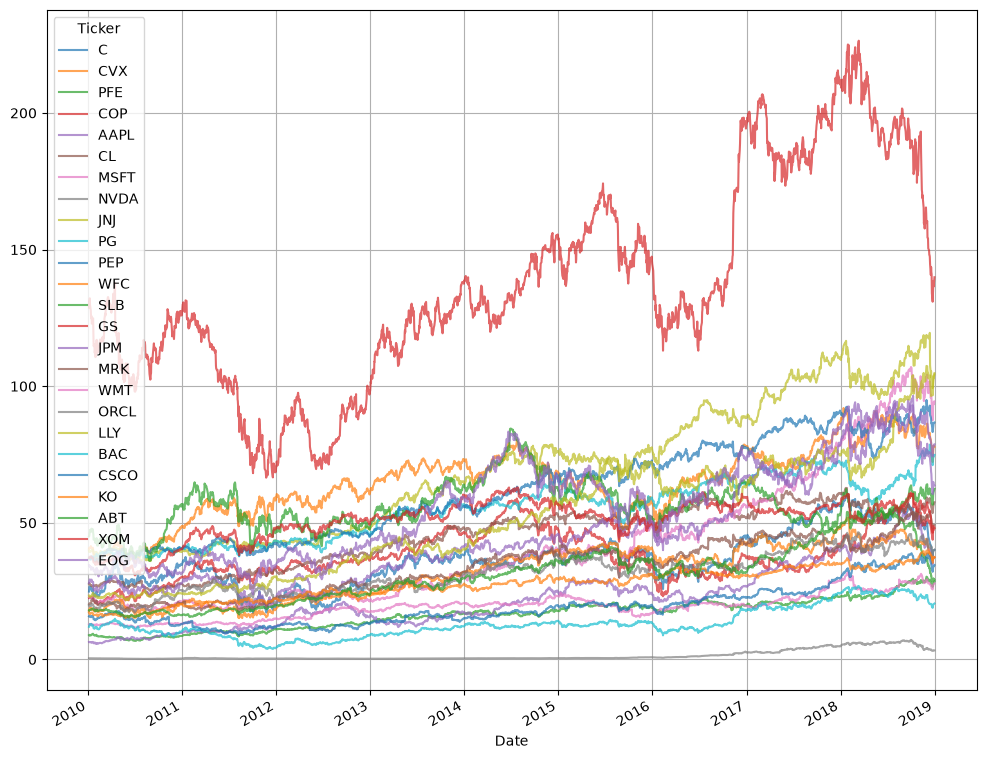

In [6]:
fig, ax = plt.subplots(figsize=(12,10))
close_data.plot(ax=ax, legend=True, alpha=0.7)
plt.grid(True)

The **daily return** of stock $i$ on day $t$ is its relative price change:

$$
r^{(i)}_t = \frac{P^{(i)}_t - P^{(i)}_{t-1}}{P^{(i)}_{t-1}}
$$


In [7]:
returns = close_data.pct_change() #percentage change, daily return
returns.dropna(inplace=True)
returns.head(2)

Ticker,C,CVX,PFE,COP,AAPL,CL,MSFT,NVDA,JNJ,PG,...,MRK,WMT,ORCL,LLY,BAC,CSCO,KO,ABT,XOM,EOG
Date,,,,,,,,,,,,,,,,,,,,,
2010-01-05,0.038235,0.007083,-0.014263,0.000951,0.001729,0.008087,0.000323,0.014603,-0.011596,0.000327,...,0.004053,-0.009957,-0.001207,-0.017588,0.032505,-0.004455,-0.012097,-0.008079,0.003904,-0.012254
2010-01-06,0.031162,0.000125,-0.003216,0.007220,-0.015906,-0.002275,-0.006137,0.006396,0.008134,-0.004743,...,0.013455,-0.002235,-0.014505,0.007388,0.011728,-0.006509,-0.000355,0.005553,0.008643,0.003329


In [8]:
# One stock per sector for the exploratory plots
tickers_to_plot = ["JPM", "AAPL", "XOM", "JNJ"]
nb_plots = len(tickers_to_plot)

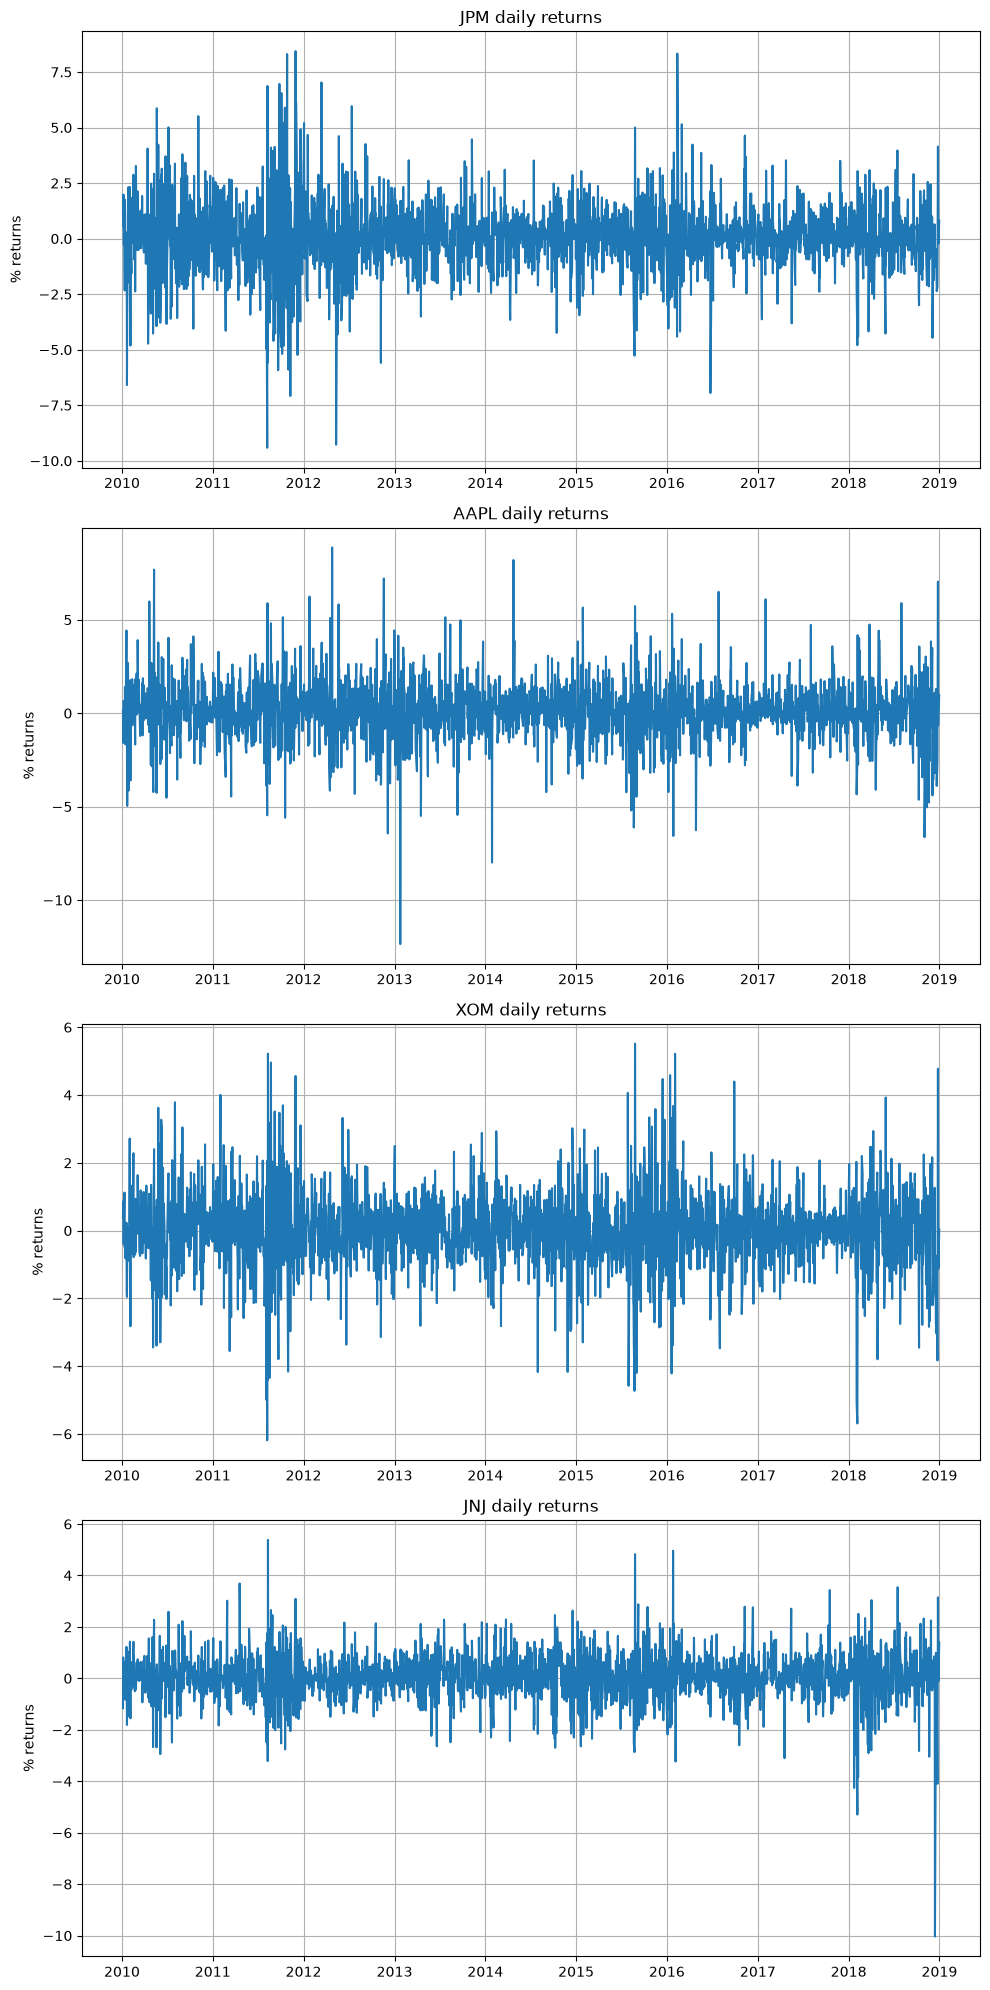

In [9]:
# Daily returns (in %) of the selected stocks
fig, ax = plt.subplots(nb_plots, figsize=(10, 20))
time = np.array(returns.index)
for i in range(nb_plots):
    ax[i].plot(time, returns[tickers_to_plot[i]].values * 100)
    ax[i].set_ylabel("% returns")
    ax[i].set_title(tickers_to_plot[i] + " daily returns")
    ax[i].grid(True)
plt.tight_layout()
plt.show()

**Autocorrelation.** We check whether one day's return helps predict the returns of the following days. Bars that stay inside the blue area (confidence interval) are not significantly different from 0.

We expect near-zero autocorrelations: **raw returns are hardly predictable**. Today's return tells us nothing about tomorrow's.

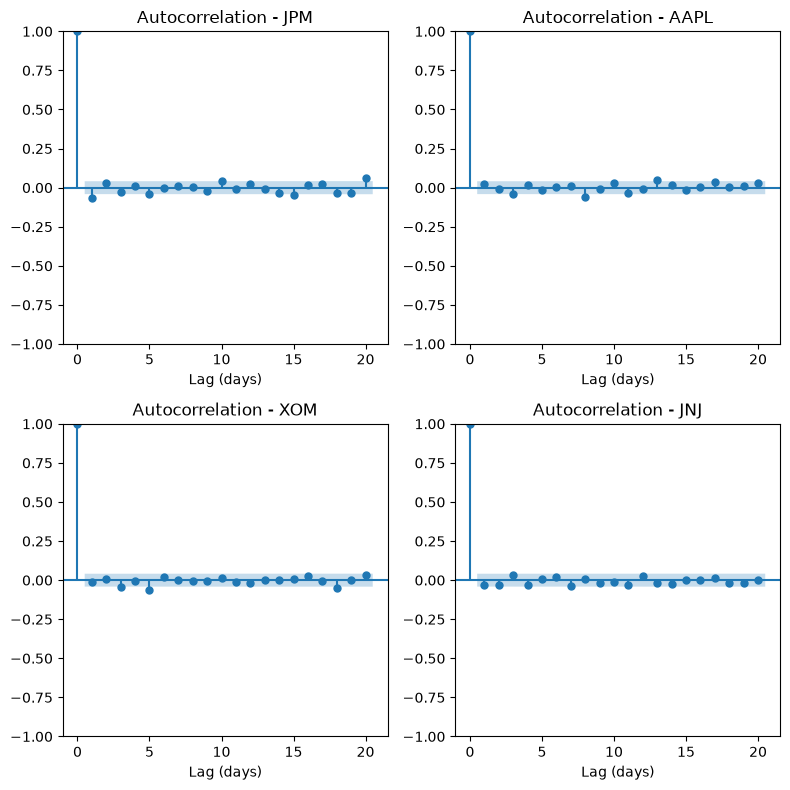

In [10]:
from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(2,2, figsize=(8,8))
for ax, ticker in zip(ax.flat, tickers_to_plot):
    plot_acf(returns[ticker], lags=20, ax=ax)
    ax.set_title(f"Autocorrelation - {ticker}")
    ax.set_xlabel("Lag (days)")

plt.tight_layout()
plt.tight_layout()

**Return distribution.** Compared with a normal distribution, daily returns are more concentrated around 0 and have **fat tails**: extreme moves are much more frequent than a Gaussian would predict.

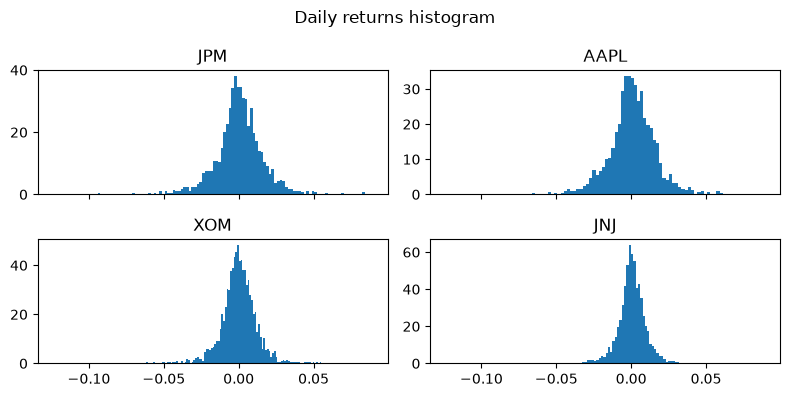

In [11]:
fig, ax= plt.subplots(2,2, sharex=True, figsize=(8,4))
plt.suptitle("Daily returns histogram")
for ax, ticker in zip(ax.flat, tickers_to_plot):
    ax.hist(returns[ticker], bins=100, density=True)
    ax.set_title(ticker)
fig.tight_layout()
plt.show()

### Correlation matrix $\Sigma$

With $N=25$ assets, the empirical correlation matrix $\Sigma$ has size $(25, 25)$. Its coefficients are defined by:

$$
\Sigma_{i,j} = \dfrac{C_{i,j}}{\sqrt{C_{i,i}\,C_{j,j}}}
$$

where $C_{i,j}$ is the empirical covariance of $r^{(i)}$ and $r^{(j)}$:

$$
C_{i,j} = \frac{1}{T-1} \sum_{k=1}^{T} \left(r^{(i)}_k - \bar{r}^{(i)}\right)\left(r^{(j)}_k - \bar{r}^{(j)}\right)
$$
and $T$ is the number of observations, here $T=2264$.

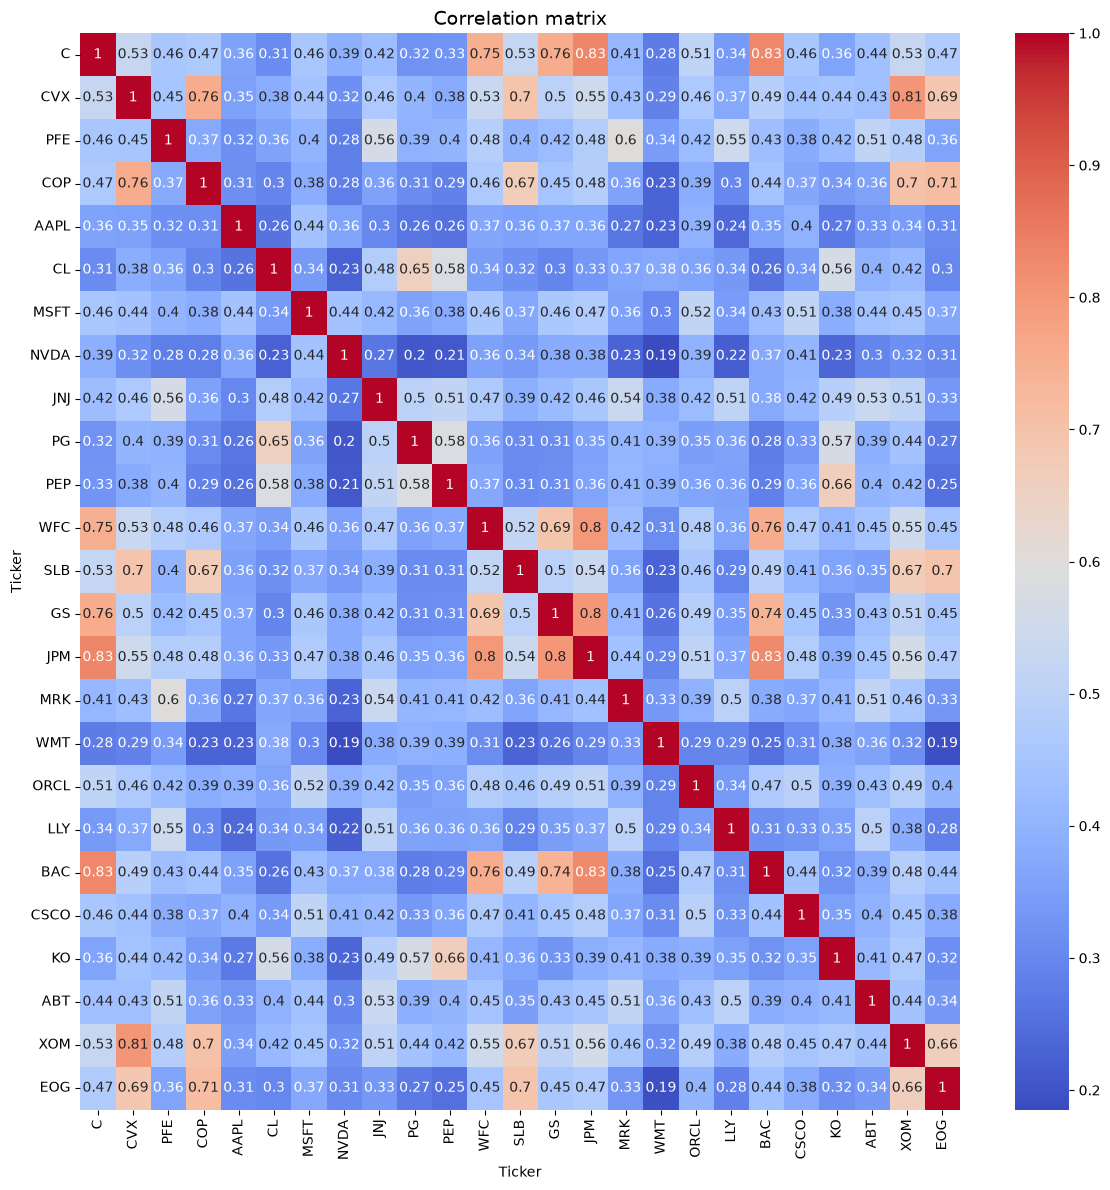

In [12]:
Sigma=returns.corr()
fig, ax = plt.subplots(1, figsize=(12,12))
sns.heatmap(Sigma, annot=True, ax=ax, cmap="coolwarm")
plt.title("Correlation matrix", fontsize=14)
plt.tight_layout()
plt.show()

### Eigenvectors of $\Sigma$

$\Sigma$ is symmetric, so it is diagonalizable in an orthonormal basis of eigenvectors. Each eigenvector is a direction along which the stocks move together. Since $\operatorname{tr}(\Sigma) = N$, the share of variance explained by the $k$-th direction is $\lambda_k / N$.

The first eigenvectors (largest eigenvalues) will define the common risk factors $F_t$ (eigenportfolios).

In [13]:
#Eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(Sigma)

#Sort them in decreasing order
eigenvalues = eigenvalues[::-1]
eigenvectors = eigenvectors[:, ::-1]

#Contribution (%) of each eigenvalue
eigenvalue_contrib = eigenvalues/np.sum(eigenvalues)*100

#Display the eigenvalues
eigen_table = pd.DataFrame([eigenvalues, eigenvalue_contrib]).T
eigen_table.columns=['eigenvalue', 'contribution (%)']
print(eigen_table.round(3))


    eigenvalue  contribution (%)
0       11.131            44.524
1        2.185             8.740
2        1.545             6.181
3        1.154             4.615
4        1.092             4.369
5        0.709             2.836
6        0.638             2.552
7        0.598             2.390
8        0.534             2.134
9        0.516             2.065
10       0.513             2.052
11       0.485             1.940
12       0.466             1.862
13       0.440             1.760
14       0.387             1.549
15       0.371             1.485
16       0.329             1.317
17       0.327             1.307
18       0.300             1.199
19       0.287             1.146
20       0.257             1.029
21       0.245             0.980
22       0.183             0.730
23       0.163             0.653
24       0.146             0.585


#### Note:
We do recover $\sum_k \lambda_k = \operatorname{tr}(\Sigma) = 25$ 

## Marchenko-Pastur theory and noise filtering

With a large number of assets ($N=25$) over a finite historical period, the empirical correlation matrix is polluted by **statistical noise** due to sampling fluctuations.

The **Marchenko-Pastur law** describes the theoretical distribution of the eigenvalues of a random correlation matrix (pure noise). It defines an upper bound $\lambda_{max}$:

$$\lambda_{max} = \left(1 + \sqrt{\frac{N}{T}}\right)^2$$

*(with $N=25$ the number of assets and $T=2264$ the number of time observations).*
Here, $\boxed{\lambda_{max}=1.22}$

All eigenvalues below $\lambda_{max}$ are considered noise.
To denoise the matrix, we consider two methods: Ledoit-Wolf shrinkage and Bouchaud-Potters clipping.



### Ledoit-Wolf shrinkage

**Principle.**
 The empirical correlation matrix $\hat\Sigma$ is unbiased but noisy: each of its $N(N-1)/2 = 300$ off-diagonal coefficients carries an estimation error. We combine it with a target matrix $F$, which is biased but very stable since it depends on few parameters:

$$
\Sigma_{LW} = (1-\delta)\,\hat\Sigma + \delta\,F, \qquad \delta \in [0,1]
$$

The coefficient $\delta$ is chosen to minimize the mean squared error $\mathbb{E}\,\|\Sigma_{LW} - \Sigma\|_F^2$ (bias-variance trade-off).

**Target: constant correlation** (Ledoit and Wolf, 2003). All off-diagonal coefficients are equal to the average correlation $\bar\rho$:

$$
F = (1-\bar\rho)\,I + \bar\rho\,\mathbf{1}\mathbf{1}^\top
$$

**Choice of $\delta$.**

$$
\hat\delta = \min\left(1,\ \frac{\sum_{i \neq j} \widehat{\operatorname{Var}}(\hat\Sigma_{ij})}{\sum_{i \neq j} \left(\hat\Sigma_{ij} - F_{ij}\right)^2}\right)
$$


In [14]:
def ledoit_wolf_shrinkage(returns, target='constant'):
    """Parameters:
    returns: array of size T*N, coefficient (i, j) is the return of stock j on day i
    target: type of target matrix (see the LW method above), 'constant' for a matrix with the same coefficient everywhere
    'identity' for a matrix proportional to the identity matrix"""

    Z = (returns - returns.mean())/returns.std()  #standardized returns
    Z = Z.values

    T, N = returns.shape

    # S is the empirical correlation matrix, symmetric positive, of size N*N
    S = returns.corr().values

    #off-diagonal indices, ~ is the negation. np.eye() is the identity matrix

    offdiag_index = ~np.eye(N, dtype=bool)

    #F is the target matrix
    if target=="constant":
        rho = S[offdiag_index].mean()
        F = (1-rho)*np.eye(N) + rho*np.ones((N,N))
    elif target=='identity':
        F = np.eye(N)
    else:
        raise ValueError("target is either 'constant' or 'identity'")

    #delta: regularization coefficient
    var_S = np.zeros((N,N))


    for i in range(N):
        for j in range(N):
            zi, zj = Z[:, i], Z[:, j]                   # standardized returns of stocks i and j
            w = zi * zj - S[i, j] / 2 * (zi**2 + zj**2) # one value per day
            var_Sij = w.var() / T
            var_S[i,j] = var_Sij

    delta = var_S[offdiag_index].sum()/((S-F)**2)[offdiag_index].sum()
    delta = min(delta,1)

    #Ledoit-Wolf matrix:
    Sigma_LW = (1-delta)*S + delta*F

    return Sigma_LW, delta

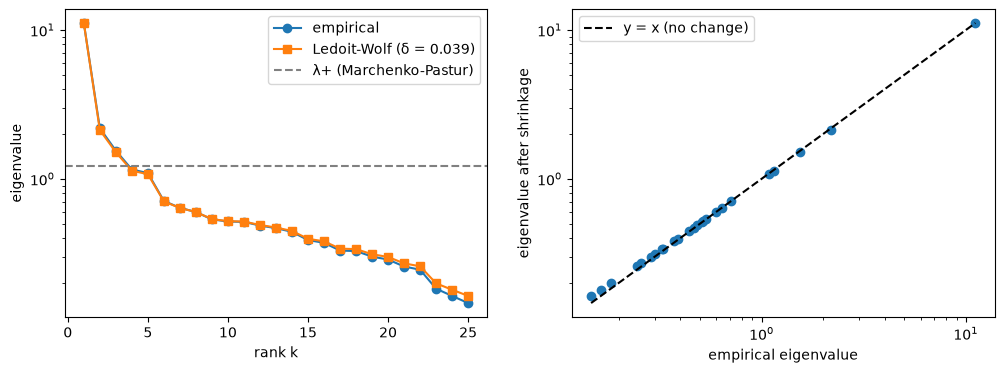

   before   after  overlap v_k
0  11.131  11.117          1.0
1   2.185   2.125          1.0
2   1.545   1.508          1.0
3   1.154   1.133          1.0
4   1.092   1.073          1.0
5   0.709   0.705          1.0


In [15]:
Sigma_LW, delta = ledoit_wolf_shrinkage(returns, target='constant')
T, N = returns.shape
lam_plus = (1 + np.sqrt(N / T))**2

# Eigenvalues and eigenvectors, sorted in decreasing order
lam, V = np.linalg.eigh(Sigma)
lam, V = lam[::-1], V[:, ::-1]
lam_lw, V_lw = np.linalg.eigh(Sigma_LW)
lam_lw, V_lw = lam_lw[::-1], V_lw[:, ::-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rank = np.arange(1, N + 1)

# 1. Spectra side by side, log scale
axes[0].plot(rank, lam, 'o-', label='empirical')
axes[0].plot(rank, lam_lw, 's-', label=f'Ledoit-Wolf (δ = {delta:.3f})')
axes[0].axhline(lam_plus, ls='--', color='grey', label='λ+ (Marchenko-Pastur)')
axes[0].set_yscale('log')
axes[0].set_xlabel('rank k')
axes[0].set_ylabel('eigenvalue')
axes[0].legend()

# 2. Before vs after: one point per eigenvalue
axes[1].scatter(lam, lam_lw)
lims = [lam.min(), lam.max()]
axes[1].plot(lims, lims, 'k--', label='y = x (no change)')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('empirical eigenvalue')
axes[1].set_ylabel('eigenvalue after shrinkage')
axes[1].legend()

plt.show()

# 3. Did the eigenvectors move? (1 = same direction; absolute value because of the sign)
overlap = np.abs(np.sum(V * V_lw, axis=0))
print(pd.DataFrame({'before': lam, 'after': lam_lw, 'overlap v_k': overlap}).head(6).round(3))

### Bouchaud-Potters spectral cleaning (clipping).
 We diagonalize $\hat\Sigma = V \Lambda V^\top$. The eigenvalues above the Marchenko-Pastur threshold $\lambda_+$ are kept (signal), the others are replaced by their mean (noise), which preserves the trace $N$. We then rebuild the matrix:

$$
\hat\Sigma_{\text{clean}} = V \Lambda_{\text{clean}} V^\top
$$

and reset its diagonal to 1 to get a correlation matrix back.

#### Implementation:
1. Compute the theoretical Marchenko-Pastur threshold $\lambda_+=\big(1+\sqrt{\dfrac{N}{T}}\big)^2$, below which eigenvalues can be treated as noise
2. Diagonalize the symmetric matrix $\Sigma=VDV^{T}$, with $V$ the orthogonal matrix of eigenvectors (spectral theorem) and $D$ the diagonal matrix of eigenvalues
3. The $k$ eigenvalues $> \lambda_+$ are kept as they are. The remaining $N-k$ (noise) are replaced by their mean $\lambda_{noise}$, which preserves the trace.
4. Build the cleaned matrix $\Sigma_{clean}=VD_{clean}V^{T}$, then renormalize it to get a unit diagonal.
Note: only the eigenvalues are cleaned, the eigenvectors are not modified. 

In [16]:
def clipping_bouchaud_potters(returns):
    """Parameters
    returns: pd.DataFrame of size N*T
    Returns Sigma_clean, the empirical correlation matrix cleaned by clipping"""

    T, N = returns.shape
    Sigma = returns.corr().values

    vals, vecs = np.linalg.eigh(Sigma)
    vals, vecs = vals[::-1], vecs[:, ::-1]
    lambda_ = (1+np.sqrt(N/T))**2

    #Keep the signal, replace the noise by its mean
    mask = vals > lambda_
    k = int(mask.sum())
    vals_clean = vals.copy()
    vals_clean[~mask] = vals[~mask].mean()

    # Rebuild the cleaned matrix
    Sigma_clean = vecs @ np.diag(vals_clean) @ vecs.T

    #Renormalize the diagonal to 1
    # np.diag(v): Extract a diagonal (if v is 2D) or construct a diagonal array (if v is 1D)
    d = np.sqrt(np.diag(Sigma_clean))
    Sigma_clean = Sigma_clean/(np.outer(d,d))

    return Sigma_clean, vals_clean, k, lambda_


In [17]:
Sigma_BP, eigenvalues_BP, k , lambda_ = clipping_bouchaud_potters(returns)
print(f"Marchenko-Pastur threshold: lambda_+ = {lambda_}")
print(f"Number of significant eigenvalues: k = {k}")

Marchenko-Pastur threshold: lambda_+ = 1.2212593882857499
Number of significant eigenvalues: k = 3


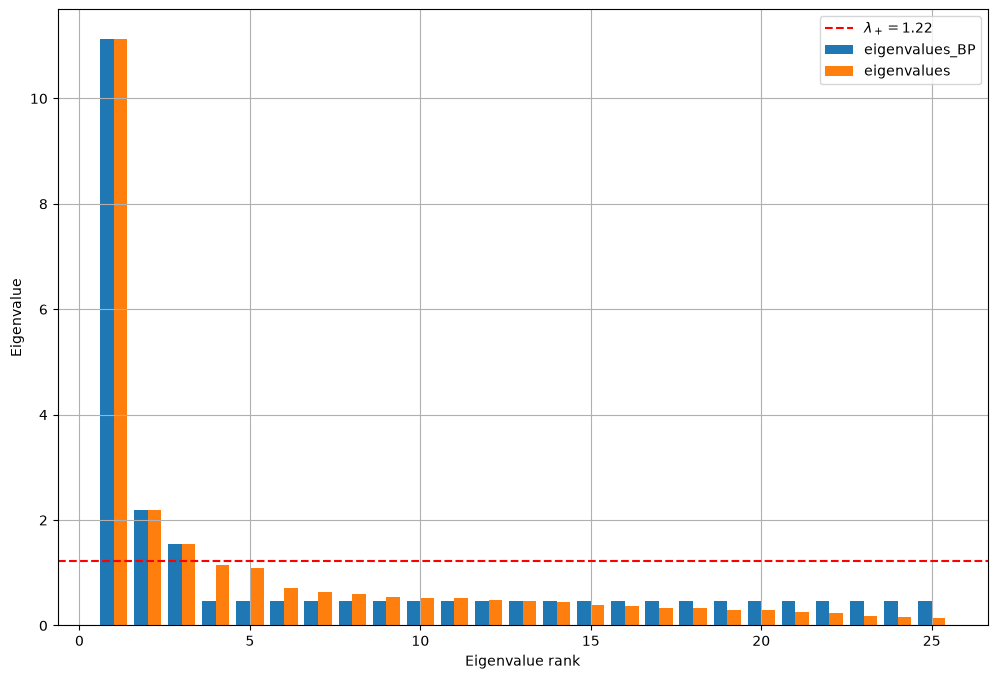

In [18]:
x = np.arange(1,N+1)
fig, ax = plt.subplots(figsize=(12,8))
ax.bar(x-0.2, eigenvalues_BP, width=0.4, label="eigenvalues_BP")
ax.bar(x+0.2, eigenvalues, width=0.4, label="eigenvalues")
ax.axhline(lambda_, color="red", linestyle="--", label=rf"$\lambda_+ = {lambda_:.2f}$")
ax.set_xlabel("Eigenvalue rank")
ax.set_ylabel("Eigenvalue")
ax.grid(True)
plt.legend()
#plt.tight_layout()
plt.show()

## Step 2: eigenportfolios, factors and residuals

**Goal.** Decompose each stock's return into a common part (market, sectors) and a part specific to the stock:

$$
r_{i,t} = \alpha_i + \beta_i^\top F_t + \varepsilon_{i,t}
$$

$F_t$ and $r_{i,t}$ are observed on the same day. What we are after are the residuals $\varepsilon_{i,t}$ (the part we will trade) and the $\beta_i$ (which will be used for hedging).

**Notation.** $R \in \mathbb{R}^{T \times N}$ the return matrix ($R_{t,i} = r_{i,t}$).

 $\sigma_i$ the standard deviation of stock $i$,

 $D = \operatorname{diag}(\sigma_1, \dots, \sigma_N)$, and

  $V_k = [v_1, \dots, v_k] \in \mathbb{R}^{N \times k}$ the first $k$ eigenvectors of $\hat\Sigma$ (here $k = 3$).

### Eigenportfolios

Each eigenvector $v_j$ defines a portfolio, which invests in stock $i$ the amount:

$$
Q_{ij} = \frac{v_j^{(i)}}{\sigma_i}, \qquad Q = D^{-1} V_k \in \mathbb{R}^{N \times k}
$$

Dividing by $\sigma_i$ puts more weight on the less volatile stocks, so that each one contributes the same amount of risk.

*Example (4 stocks with the same volatility):*

- $v_1 = \frac{1}{2}(1, 1, 1, 1)$ buys all the stocks: this is the **market**.
- $v_2 = \frac{1}{2}(1, 1, -1, -1)$ buys the two banks and short-sells the two oil companies: this is a **banks versus energy** portfolio. Its weights sum to 0: on a day when everything rises by 1%, it earns nothing.

An eigenvector is only defined up to its sign: $-v_2$ (long energy, short banks) is just as valid. This changes nothing in the model, since the $\beta$ change sign at the same time.

### Factor returns

The return of eigenportfolio $j$ on day $t$ is:

$$
F_{t,j} = \sum_{i=1}^{N} \frac{v_j^{(i)}}{\sigma_i}\, r_{i,t}, \qquad F = R\,Q \in \mathbb{R}^{T \times k}
$$

Each column of $F$ is the time series of one factor; each row is the "daily bulletin", common to all stocks. For example, a row $(3, 2)$ means: the market went up and banks beat energy; a row $(-3, 0)$: everything fell together, with no sector effect.

The factors are uncorrelated and $\operatorname{Var}(F_j) = \lambda_j$. Their scale is arbitrary (the weights do not sum to 1): if a factor is multiplied by 2, its $\beta$ is divided by 2 and the residual does not change.

### Regression and residuals

For each stock $i$, we regress its $T$ returns on the $k$ factors by least squares. With $X = [\mathbf{1} \;\; F] \in \mathbb{R}^{T \times (k+1)}$:

$$
\hat\Theta = (X^\top X)^{-1} X^\top R \in \mathbb{R}^{(k+1) \times N}, \qquad E = R - X\hat\Theta \in \mathbb{R}^{T \times N}
$$

The first row of $\hat\Theta$ contains the $\alpha_i$, the next $k$ rows the $\beta_i$, and $E_{t,i} = \varepsilon_{i,t}$.

**Check (static case).** When the PCA and the regression use the same data, since the factors are uncorrelated, we directly get:

$$
\beta_{ij} = \sigma_i\, v_j^{(i)}
$$

**Interpreting the residuals.** The residual is the part of the standardized returns orthogonal to the $k$ retained directions. Its correlation matrix only contains the rest of the spectrum, $\sum_{j > k} \lambda_j v_j v_j^\top$: the sector blocks of the heatmap should have disappeared. If one remains, a factor is missing.

### The hedged portfolio

Buying €1 of stock $i$ and selling $\beta_{ij}$ units of each eigenportfolio $j$ gives the P&L:

$$
r_{i,t} - \sum_{j=1}^{k} \beta_{ij}\, F_{t,j} = \alpha_i + \varepsilon_{i,t}
$$

The position is then insensitive to the market and to the sectors: only the stock's own move remains. This cumulative P&L, $X_{i,t} = \sum_{s \le t} \varepsilon_{i,s}$, is what we model in the next step with an Ornstein-Uhlenbeck process.

In [19]:
#Principal components
PC = eigenvectors[:,:k]

#standard deviation of each stock: (N,)
std = returns.std()

#Weights of each eigenportfolio: (N,k) Each column represents the weights of portfolio
eigenportfolio_weights = pd.DataFrame(PC/std.values[:, None], index=returns.columns, columns=[f"F{j+1}" for j in range(k)])

eigenportfolio_weights

,F1,F2,F3
Ticker,,,
C,11.621352,-11.847912,-11.370450
CVX,17.189087,-7.493987,26.525737
PFE,17.731516,11.232978,-6.603290
COP,11.976725,-9.827985,24.324961
AAPL,9.627083,-2.452847,-4.358400
CL,16.939287,31.972554,6.363962
MSFT,13.511384,0.520279,-7.201601
NVDA,5.822175,-3.996942,-4.926871
JNJ,22.087448,23.906464,-4.661089


The coefficient $F_{t,j}$ represents the return of portfolio $j$ on day $t$. It is the sum of the returns of the $N$ stocks, weighted by their weights Q.
$$F_{t,j}=\sum\limits_{l=1}^{N}Q_{l,j}R_{t,l}=R.Q \quad \in (N,k)$$

In [20]:
#F : (T,k) represents the returns of the portfolios on day t
#Each column j is the time series of returns of eigenportfolio j
#Each row t is the "daily bulletin": what the k eigenportfolios did on day t

principal_returns = returns @ eigenportfolio_weights
principal_returns.shape

(2263, 3)

### Approach 1: rolling OLS regression

OLS for stock $i$:

the dependent variable is its return series, column $i$ of returns, i.e. $T = 2264$ values;
the explanatory variables are the $k = 3$ factor return series (the factor columns), plus a constant.

Each day $t$ gives one observation: the stock's return on that day, and what the three factors did on the same day.

$$\underbrace{r_{i,t}}_{\text{stock } i,\ \text{day } t} = \alpha_i + \beta_{i1}\,F_{t,1} + \beta_{i2}\,F_{t,2} + \beta_{i3}\,F_{t,3} + \varepsilon_{i,t}, \qquad t = 1, \dots, T$$
We therefore look for the coefficients $\beta_i = (\alpha_i, \beta_{i,1}, \beta_{i,2}, \beta_{i,3})$ that minimize the least squares error: $$\argmin_{\alpha_i,\,\beta_i} \sum_{t=1}^{T} \varepsilon_{i,t}^2 = \argmin_{\alpha_i,\,\beta_i} \sum_{t=1}^{T} \Big( r_{i,t} - \alpha_i - \sum_{j} \beta_{ij} F_{t,j} \Big)^2$$


**Rolling**: instead of a single regression per stock over the whole period, we run a new one every day, on the last $W$ days only.

With $W = 60$:

| Estimation day | Days used for the regression |
|---|---|
| $t = 61$ | 1 to 60 |
| $t = 62$ | 2 to 61 |
| $t = 63$ | 3 to 62 |
| … | … |

We thus get a sequence of $\beta_{i,t}$ that evolves over time, instead of a single $\beta_i$.

In [21]:
from statsmodels.regression.rolling import RollingOLS
#Predictors X : principal_returns (k features, T observations) + constant column
X = sm.add_constant(principal_returns)

#Estimating OLS parameters for each stock
params = {}
for ticker in returns.columns:
    params[ticker] = RollingOLS(returns[ticker], X, window=60).fit().params

params = pd.concat(params, axis=1)
params = params.shift(1)

params.tail(5)

C                                     CVX            \
               const        F1        F2        F3     const        F1   
Date                                                                     
2018-12-24 -0.001662  0.003549 -0.002799 -0.002066  0.001634  0.003121   
2018-12-26 -0.001703  0.003476 -0.002870 -0.002169  0.001724  0.003091   
2018-12-27 -0.001672  0.003426 -0.002825 -0.002173  0.001924  0.003167   
2018-12-28 -0.001570  0.003438 -0.002828 -0.002148  0.002076  0.003189   
2018-12-31 -0.001538  0.003439 -0.002828 -0.002171  0.002042  0.003188   

                                     PFE            ...       ABT            \
                  F2        F3     const        F1  ...        F2        F3   
Date                                                ...                       
2018-12-24 -0.001510  0.005066  0.001063  0.002558  ... -0.000280 -0.002132   
2018-12-26 -0.001566  0.005037  0.000948  0.002572  ... -0.000325 -0.002172   
2018-12-27 -0.001576  0.005085  0.000822  0.002531  ... -0.000377 -0.002089   
2018-12-28 -0.001530  0.005077  0.000903  0.002542  ... -0.000350 -0.002122   
2018-12-31 -0.001529  0.005081  0.000964  0.002543  ... -0.000356 -0.002137   

                 XOM                                     EOG            \
               const        F1        F2        F3     const        F1   
Date                                                                     
2018-12-24 -0.000359  0.002796 -0.000931  0.003597  0.000857  0.004353   
2018-12-26 -0.000360  0.002836 -0.000887  0.003650  0.000700  0.004373   
2018-12-27 -0.000307  0.002808 -0.000853  0.003653  0.000443  0.004312   
2018-12-28 -0.000286  0.002809 -0.000877  0.003680  0.000529  0.004318   
2018-12-31 -0.000518  0.002803 -0.000868  0.003694  0.000416  0.004315   

                                
                  F2        F3  
Date                            
2018-12-24 -0.003639  0.008798  
2018-12-26 -0.003576  0.008806  
2018-12-27 -0.003591  0.008751  
2018-12-28 -0.003671  0.008845  
2018-12-31 -0.003667  0.008852  

[5 rows x 100 columns]

In [22]:
principal_returns.columns

Index(['F1', 'F2', 'F3'], dtype='str')

**Daily residuals of each stock**
$$\varepsilon_{i,t} = r_{i,t} - \alpha_{i,t} - \sum_{j} \beta_{ij,t}\, F_{t,j}$$

In [23]:
residuals = {}
for ticker in returns.columns:
    residuals[ticker]=returns[ticker] - params[ticker, "const"]
    for beta in principal_returns.columns:
        residuals[ticker]-=params[ticker, beta]*principal_returns[beta]

residuals = pd.concat(residuals, axis=1)
residuals.tail(5)

,C,CVX,PFE,COP,AAPL,CL,MSFT,NVDA,JNJ,PG,...,MRK,WMT,ORCL,LLY,BAC,CSCO,KO,ABT,XOM,EOG
Date,,,,,,,,,,,,,,,,,,,,,
2018-12-24,0.008229,0.004256,-0.002605,-0.008123,0.010204,0.009253,-0.008002,0.020999,-0.004541,-0.007046,...,0.003468,0.011422,-0.003183,0.005363,-0.007453,0.000881,-0.009314,0.004158,-0.004639,-0.003717
2018-12-26,-0.004149,0.006259,-0.003395,0.008517,0.009496,-0.010091,-0.000723,-0.030158,-0.006817,0.004477,...,-0.001157,0.022199,-0.001076,-0.001411,0.016160,-0.012892,-0.002465,0.013512,-0.002284,-0.005062
2018-12-27,0.002450,0.009718,0.003838,0.004412,-0.014037,-0.006607,-0.006453,-0.017412,-0.007345,0.006131,...,0.006746,0.002910,0.000164,0.003674,0.004287,-0.002639,0.001737,0.002389,-0.002336,-0.007670
2018-12-28,0.003550,-0.001126,0.001537,-0.001544,0.002810,0.002044,-0.009456,0.020553,-0.000263,-0.010082,...,-0.001876,0.005575,-0.003294,0.009998,-0.000083,-0.004444,-0.007538,0.004593,-0.005609,-0.002673
2018-12-31,-0.003795,-0.000776,0.005499,0.009716,-0.001743,-0.004816,-0.004192,-0.020194,0.006305,0.001054,...,0.003902,0.003023,-0.002824,0.003035,-0.002042,-0.001784,-0.002806,0.003979,-0.000829,0.000553


In [24]:
residuals.dropna(inplace=True)
cumulative_residuals = np.cumsum(residuals)
cumulative_residuals.head()

,C,CVX,PFE,COP,AAPL,CL,MSFT,NVDA,JNJ,PG,...,MRK,WMT,ORCL,LLY,BAC,CSCO,KO,ABT,XOM,EOG
Date,,,,,,,,,,,,,,,,,,,,,
2010-04-01,0.030411,-0.000168,-0.004580,0.001746,-0.008554,0.002996,-0.007669,-0.024035,0.005689,-0.001162,...,0.003838,-0.001150,-0.013352,-0.004073,0.006582,-0.013756,0.002390,0.002384,-0.000426,0.004296
2010-04-05,0.042638,0.001875,-0.008609,0.009509,-0.011444,0.003258,-0.004574,-0.027235,-0.000419,0.009362,...,-0.004088,0.005544,-0.007942,0.011085,-0.000352,-0.005378,-0.000384,-0.001258,-0.001736,-0.000168
2010-04-06,0.035928,0.004769,-0.000470,0.007035,-0.013362,-0.000632,-0.003257,-0.060112,-0.000525,0.002292,...,-0.004814,0.008740,0.000578,0.011656,0.004805,-0.007002,-0.004654,-0.004004,-0.006367,-0.006018
2010-04-07,0.046962,-0.003561,0.014167,-0.005396,-0.014621,0.006190,-0.000682,-0.059962,0.000670,-0.002524,...,-0.010420,0.009410,0.005014,0.016470,0.004776,-0.004078,-0.004641,-0.009430,-0.015998,0.051573
2010-04-08,0.062792,-0.008207,0.022530,0.001351,-0.029699,0.000118,0.016897,-0.090359,-0.003837,0.000435,...,-0.009163,0.014847,0.000113,0.016962,-0.003845,-0.011921,-0.002392,-0.014765,-0.015239,0.058190


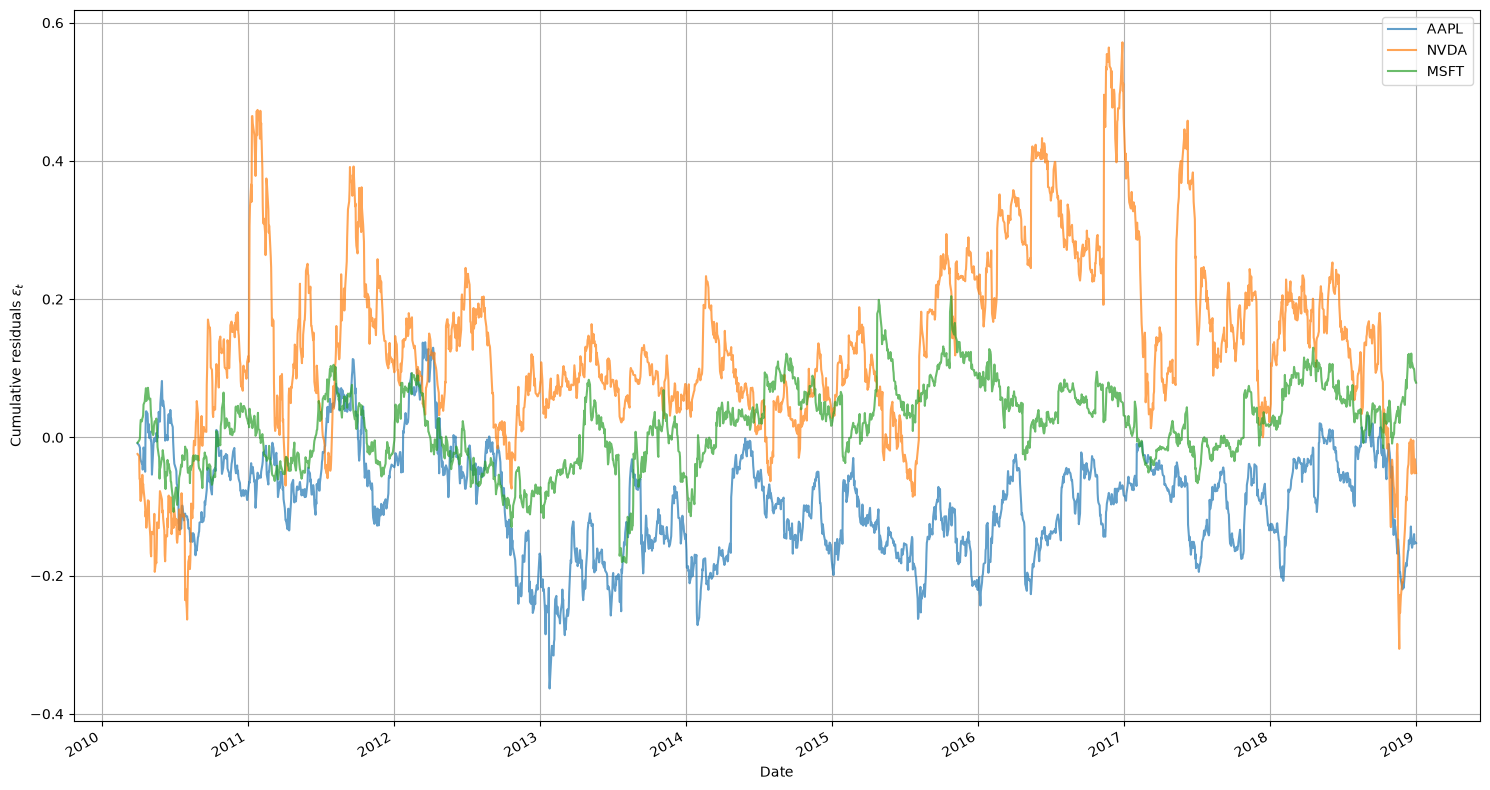

In [25]:
fig, ax = plt.subplots(figsize=(15,8))
cumulative_residuals[['AAPL', 'NVDA', 'MSFT']].plot(legend=True, ax=ax, alpha=0.7)
ax.grid(True)
ax.set_ylabel(r"Cumulative residuals $\epsilon_t$")
plt.tight_layout()
plt.show()

**Augmented Dickey-Fuller (ADF) test**: on ``cumulative_residuals``, we test the null hypothesis $H_0$: random walk, against $H_1$: mean-reverting process. 

In [26]:
from statsmodels.tsa.stattools import adfuller

pvals = [adfuller(cumulative_residuals[t].dropna(), result_object=True).pvalue for t in cumulative_residuals.columns]
p_values = pd.DataFrame({"p_value": pvals}, index=cumulative_residuals.columns)
p_values.sort_values(by="p_value", inplace=True)
print("Dickey-Fuller test run on cumulative residuals of each stock")
p_values

Dickey-Fuller test run on cumulative residuals of each stock


,p_value
JNJ,5.001908e-07
MRK,1.516243e-05
ABT,2.310988e-05
CSCO,3.505043e-05
PG,4.788715e-05
WMT,6.159151e-05
AAPL,1.596150e-04
LLY,1.881537e-04
MSFT,1.901142e-04
WFC,2.062494e-04


**Interpreting the p-values**

Out of 25 stocks, 21 have a Dickey-Fuller p-value < 0.05: we reject the null hypothesis (random walk), which shows the mean-reverting behavior of the cumulative residuals.

The four p-values > 0.05 concern the energy sector: XOM (0.44), EOG (0.12), SLB (0.055), with CVX and COP higher than most of the others. My hypothesis: with only $k = 3$ factors, the oil price is not fully captured. During the 2014-2016 oil crash, oil companies may have followed a common trend that stays in their residuals, and such a persistent trend has nothing to do with mean reversion.

## Step 3: Modelling the cumulative residuals with an Ornstein-Uhlenbeck process

We cumulate the residuals of each stock over the window:

$$
X_{i,t} = \sum_{s \le t} \varepsilon_{i,s}
$$

$X_{i,t}$ is the cumulative performance of the hedged portfolio (stock bought, factors sold): how much better or worse the stock did than what the market and its sector explain.

We assume that $X$ follows an Ornstein-Uhlenbeck process:

$$
dX_t = \kappa\,(m - X_t)\,dt + \sigma\,dW_t
$$

The first term pulls $X$ back towards its equilibrium level $m$, all the more strongly as it is far from it ($\kappa > 0$ is the speed of mean reversion). The second term is random noise. On average, the gap to equilibrium decays exponentially:

$$
\mathbb{E}[X_t] - m = (X_0 - m)\,e^{-\kappa t}
$$

and it is halved after the half-life $\tau = \ln 2 / \kappa$.

**Estimation.** Discretized with a step $\Delta t = 1$ day, the process is an AR(1):

$$
X_{n+1} = a + b\,X_n + \zeta_n, \qquad b = e^{-\kappa}, \qquad a = m\,(1 - b)
$$

We estimate $a$ and $b$ by least squares over the window, then:

$$
\kappa = -\ln b, \qquad m = \frac{a}{1-b}, \qquad \sigma_{eq} = \sqrt{\frac{\operatorname{Var}(\zeta)}{1 - b^2}}
$$

$\sigma_{eq}$ is the standard deviation of $X$ around $m$ once the process has stabilized. We only keep stocks with $0 < b < 1$ and a half-life that is short compared with the window.

**s-score.** The current distance to equilibrium, in number of standard deviations:

$$
s_i = \frac{X_{i,t} - m_i}{\sigma_{eq,i}}
$$

If $s_i$ is strongly positive, the stock has risen too much relative to its factors: we sell the hedged portfolio, betting on a return towards $m$. If $s_i$ is strongly negative, we buy it. Dividing by $\sigma_{eq}$ makes the signal comparable from one stock to another, so the same thresholds can be used for all of them.

#### Implementation

For each day $t$ and each stock $i$:

1. **Window.** Take the last $W = 60$ residuals $\varepsilon_{i,t-W+1}, \dots, \varepsilon_{i,t}$ and cumulate them: $X_n = \sum_{s \le n} \varepsilon_{i,s}$.
2. **AR(1) regression.** Regress $X_{n+1}$ on $X_n$ by least squares, which gives $a$, $b$ and the variance of the residuals $\operatorname{Var}(\zeta)$.
3. **Filter.** If $b \le 0$ or $b \ge 1$, the model is not valid. There is no mean reversion and the stock is not traded that day.
4. **Ornstein-Uhlenbeck parameters.**

$$
\kappa = -\ln b, \qquad m = \frac{a}{1-b}, \qquad \sigma_{eq} = \sqrt{\frac{\operatorname{Var}(\zeta)}{1-b^2}}, \qquad \tau = \frac{\ln 2}{\kappa}
$$

   The stock is also discarded if its half-life $\tau$ is too long (here $\tau > W/2=30\text{ days}$).

5. **s-score.** $s_{i,t} = (X_W - m)/\sigma_{eq}$, where $X_W$ is the last value of the cumulative residual.

We get a table of s-scores with the same format as `returns` (one row per day, one column per stock), with `NaN` on the days when the stock is filtered out. It is used in the next step to open and close positions.

**Validation.** Before using the real residuals, we test the function on a simulated process $X_{n+1} = a + b\,X_n + \zeta_n$ with known $a$ and $b$: the estimation should recover them.

In [27]:
from scipy.stats import linregress

def OU_discrete_params(X):
    """X : cumulative residuals of one stock over the window
    Returns a, b and the variance of the noise zeta of the AR(1) X_{n+1} = a + b X_n + zeta_n"""
    X = np.asarray(X)
    Xn, Xn1 = X[:-1], X[1:]

    reg = linregress(Xn, Xn1)         # regression of X_{n+1} on X_n
    a, b = reg.intercept, reg.slope

    zeta = Xn1 - a - b * Xn
    var_zeta = np.var(zeta, ddof=2)   # 2 estimated parameters (a and b)
    return {"a":a , "b" : b, "var_zeta":var_zeta}

def OU_params(X):
    """Ornstein-Uhlenbeck parameters and s-score, or None if there is no mean reversion"""

    d = OU_discrete_params(X)
    a, b, var_zeta = d["a"], d["b"], d["var_zeta"]

    if b <= 0 or b >= 1:
        return None

    kappa = -np.log(b)
    m = a / (1 - b)
    sigma_eq = np.sqrt(var_zeta / (1 - b**2))
    tau = np.log(2) / kappa                    # half-life, in days
    s = (np.asarray(X)[-1] - m) / sigma_eq     # s-score of the last day

    return {"kappa": kappa, "m": m, "sigma_eq": sigma_eq, "tau": tau, "s": s}


def simulate_OU(a, b, var_zeta, N=60, X_0=0, seed=42):

    rng = np.random.default_rng(seed)
    X = np.zeros(N)
    X[0] = X_0

    for i in range(1, N):
        X[i] = a + b * X[i-1] + rng.normal(0, np.sqrt(var_zeta))
    return X


def s_score(X):
    """s-score of the last day of the window, or NaN if the stock is filtered out"""
    OU_stochastic_params = OU_params(X)
    if OU_stochastic_params is None or OU_stochastic_params["tau"]>30: #no mean reversion, or too slow
        return np.nan

    return OU_stochastic_params["s"]

In [28]:
X=simulate_OU(0.2,0.3,0.1, N=10000)
print(OU_discrete_params(X))
print("The estimated parameters match the true parameters")

{'a': np.float64(0.19469460204662384), 'b': np.float64(0.3073650569451806), 'var_zeta': np.float64(0.1012851272889475)}
The estimated parameters match the true parameters


In [29]:
s_scores = cumulative_residuals.rolling(60).apply(s_score, raw=True)
s_scores.describe()


,C,CVX,PFE,COP,AAPL,CL,MSFT,NVDA,JNJ,PG,...,MRK,WMT,ORCL,LLY,BAC,CSCO,KO,ABT,XOM,EOG
count,1982.000000,1896.000000,1917.000000,1899.000000,1797.000000,1972.000000,1983.000000,1876.000000,1950.000000,1846.000000,...,1921.000000,1912.000000,1932.000000,1906.000000,1931.000000,1896.000000,1891.000000,1905.000000,1845.000000,1858.000000
mean,-0.093505,-0.038914,0.109477,0.006504,-0.040705,-0.047945,-0.022080,0.009131,-0.022134,-0.016933,...,0.035476,0.018931,0.024389,-0.042447,0.074611,-0.153766,0.003690,-0.034861,-0.053275,0.074253
std,0.880004,0.889771,0.901829,0.885253,0.912459,0.991223,0.904098,0.904325,0.905166,0.928260,...,0.897240,0.915207,0.919076,0.923954,0.873387,0.900912,0.922111,0.941216,0.960186,0.897791
min,-2.439500,-3.385046,-2.870627,-2.596698,-3.583162,-3.366921,-2.662243,-3.247215,-4.940439,-2.416404,...,-3.012401,-3.733568,-3.793649,-2.717187,-2.907952,-3.278011,-2.853548,-2.525591,-2.845787,-2.759729
25%,-0.723317,-0.673326,-0.499460,-0.588405,-0.646295,-0.743361,-0.681871,-0.651779,-0.633219,-0.696111,...,-0.544321,-0.574837,-0.551104,-0.661881,-0.516193,-0.747136,-0.644763,-0.755154,-0.763895,-0.551963
50%,-0.148230,-0.015050,0.162438,-0.059437,-0.098097,-0.084209,0.032664,-0.018561,0.008372,-0.087379,...,0.041333,0.013451,0.050206,-0.115786,0.121090,-0.180112,-0.002916,-0.018728,-0.042848,0.128946
75%,0.518895,0.626904,0.760101,0.682613,0.632428,0.655986,0.611148,0.659946,0.578941,0.688155,...,0.662977,0.633928,0.685499,0.623987,0.619821,0.439875,0.659719,0.652255,0.594601,0.677945
max,3.043982,3.365114,3.250286,3.339781,2.844219,3.338833,3.586734,5.592322,2.852059,3.226285,...,4.013266,2.979788,2.772254,3.108364,2.397305,3.123049,2.891660,2.716575,3.196974,2.810244


**Interpretation** The $s$-score (signal score) is the normalized gap between the current value of an asset and its theoretical value (the value explained by its factors).
If $X$ (cumulative residuals) has followed an Ornstein-Uhlenbeck process for long enough, it is in its stationary regime, where it follows the distribution:
$$ X_t \sim \mathcal{N}(m,\sigma_{eq}^2) $$
By definition, $s_t = \dfrac{X_t-m}{\sigma_{eq}}$, which implies $s_t \sim \mathcal{N}(0,1)$.

This is consistent with the table above: the s-scores do have an empirical mean close to 0 and a standard deviation close to 1.

## Step 4: trading strategy

For each stock $i$, we hold a position $q_{i,t} \in \{-1, 0, +1\}$ on its hedged portfolio (stock bought, factors sold). It evolves with the s-score:

$$
q_{i,t} =
\begin{cases}
+1 & \text{if } q_{i,t-1} = 0 \text{ and } s_{i,t} < -1.25 \quad \text{(open a long)} \\
-1 & \text{if } q_{i,t-1} = 0 \text{ and } s_{i,t} > 1.25 \quad \text{(open a short)} \\
0 & \text{if } q_{i,t-1} = -1 \text{ and } s_{i,t} < 0.75 \quad \text{(close the short)} \\
0 & \text{if } q_{i,t-1} = +1 \text{ and } s_{i,t} > -0.5 \quad \text{(close the long)} \\
q_{i,t-1} & \text{otherwise}
\end{cases}
$$

The thresholds are those of Avellaneda and Lee (2010), chosen empirically.

**Intuition.** Under the Ornstein-Uhlenbeck model, the expected change of the cumulative residual over $h$ days is:

$$
\mathbb{E}[X_{t+h} - X_t] = (m - X_t)\left(1 - e^{-\kappa h}\right) = -\,s_t\,\sigma_{eq}\left(1 - e^{-\kappa h}\right)
$$

The expected gain is proportional to $-s_t$: the larger the gap to equilibrium, the stronger the expected reversion, and always in the direction of $m$. We therefore sell when $s$ is strongly positive (the stock has risen too much relative to its factors) and buy when it is strongly negative.

- **Entry at $|s| > 1.25$**: we only bet on significant gaps. If $s \sim \mathcal{N}(0,1)$, this happens about 21% of the time.
- **Exit before $s = 0$**: the end of the reversion brings little (the expected gain is proportional to $s$), while the risk of the position keeps running.
- **Different entry and exit thresholds** (hysteresis): otherwise, an s-score hovering around a threshold would open and close the position every day, paying fees each time.


#### Implementation

1. **Positions.** We go through the days in order and, for each stock, apply the opening and closing rules from the previous day's position $q_{i,t-1}$ and the current s-score $s_{i,t}$. Since a position stays open from one day to the next, we keep track of each stock's current position. If the stock is filtered out that day (missing s-score), the position is closed. The result is a `positions` table of values $-1$, $0$ or $+1$, with the same format as `returns`.

2. **Position size.** Each position uses a fraction $1/N$ of the capital: $P_{i,t} = q_{i,t}/N$.

3. **Idealized P&L.** Each position earns the return of its hedged portfolio, using the previous day's position (decided at the close of $t-1$):

$$
\text{P\&L}_t = \sum_{i=1}^{N} P_{i,t-1}\left(\alpha_i + \varepsilon_{i,t}\right)
$$

In [30]:
def positions_from_s(s_scores, entry=1.25, exit_short=0.75, exit_long=-0.5):
    """+1 = long, -1 = short, 0 = no position, for each stock and each day"""
    positions = pd.DataFrame(0.0, index=s_scores.index, columns=s_scores.columns)
    current = pd.Series(0.0, index=s_scores.columns)
    for t in s_scores.index:
        s = s_scores.loc[t]
        open_short = (current == 0) & (s > entry)
        open_long = (current == 0) & (s < -entry)
        close_short = (current == -1) & (s < exit_short)
        close_long = (current == 1) & (s > exit_long)
        current[open_short] = -1
        current[open_long] = 1
        current[close_short | close_long | s.isna()] = 0   # filtered stock: close the position
        positions.loc[t] = current
    return positions


In [31]:
positions = positions_from_s(s_scores)
positions.head()

,C,CVX,PFE,COP,AAPL,CL,MSFT,NVDA,JNJ,PG,...,MRK,WMT,ORCL,LLY,BAC,CSCO,KO,ABT,XOM,EOG
Date,,,,,,,,,,,,,,,,,,,,,
2010-04-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2010-04-05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2010-04-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2010-04-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2010-04-08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### P&L computation

**Return of a hedged portfolio.** From the decomposition

$$
r_{i,t} = \alpha_i + \beta_i^\top F_t + \varepsilon_{i,t}
$$

buying stock $i$ and selling $\beta_{ij}$ units of each eigenportfolio $j$ earns:

$$
r_{i,t} - \beta_i^\top F_t = \alpha_i + \varepsilon_{i,t}
$$

The market and sector moves cancel out; only the drift $\alpha_i$ and the stock's own move $\varepsilon_{i,t}$ remain. The constant $\alpha_i$ is not hedged, since it is not an asset that can be sold: it stays in the return of the hedged portfolio. In code, this is `residuals + alphas`.

**Strategy P&L.** Each position uses a fraction $1/N$ of the capital, and the position held on day $t$ is the one decided at the close of $t-1$:

$$
\text{P\&L}_t = \frac{1}{N}\sum_{i=1}^{N} q_{i,t-1}\left(\alpha_i + \varepsilon_{i,t}\right)
$$

A long ($q = +1$) earns the return of the hedged portfolio, a short ($q = -1$) earns its opposite, and a stock with no position ($q = 0$) earns nothing. The one-day lag (`positions.shift(1)`) is essential: without it, we would use the return of day $t$ to decide the position of day $t$.

In [32]:
#fraction of the capital per position, array (T,N)
P = positions / N
alphas=params.xs("const", axis=1, level=1)
pnl_gross = (P.shift(1)*(residuals+alphas)).sum(axis=1).dropna()
pnl_gross.describe()

count    2263.000000
mean        0.000024
std         0.001079
min        -0.008033
25%        -0.000500
50%         0.000000
75%         0.000549
max         0.013713
dtype: float64

                           no fees  with fees
annualized return (%)         0.63      -0.14
annualized volatility (%)     1.74       1.73
Sharpe                        0.36      -0.08
max drawdown (%)             -4.22      -6.58
winning days (%)             49.41      48.14
correlation with market      -0.00      -0.00


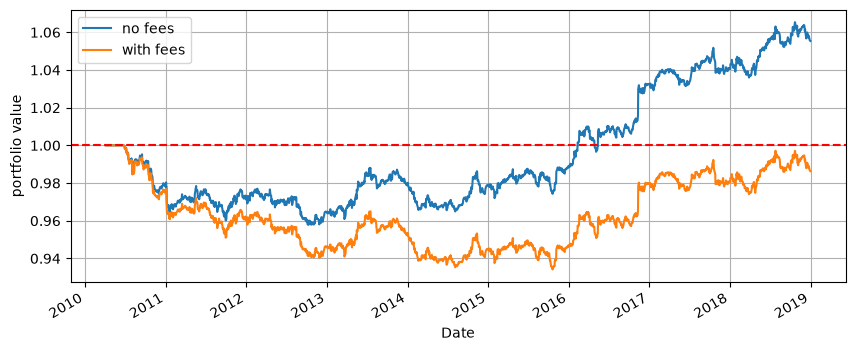

In [33]:
N = positions.shape[1]
cost = 0.0005                                  # 5 basis points per unit traded

# 1. Daily P&L: previous day's position x return of the hedged portfolio
hedged_return = residuals + alphas
pnl_gross = (positions.shift(1) / N * hedged_return).sum(axis=1)
pnl_gross = pnl_gross.loc[positions.index[1:]]   # keep the days when the strategy is running

# 2. Fees: proportional to position changes
fees = cost * (positions.diff().abs() / N).sum(axis=1).loc[pnl_gross.index]
pnl_net = pnl_gross - fees

# 3. Metrics
def summary(pnl):
    value = (1 + pnl).cumprod()               # portfolio value, starting at 1
    return pd.Series({
        "annualized return (%)": 100 * pnl.mean() * 252,
        "annualized volatility (%)": 100 * pnl.std() * np.sqrt(252),
        "Sharpe": pnl.mean() / pnl.std() * np.sqrt(252),
        "max drawdown (%)": 100 * (value / value.cummax() - 1).min(),
        "winning days (%)": 100 * (pnl > 0).mean(),
        "correlation with market": pnl.corr(returns.mean(axis=1)),
    })

print(pd.DataFrame({"no fees": summary(pnl_gross), "with fees": summary(pnl_net)}).round(2))

# 4. Portfolio value over time
fig, ax = plt.subplots(figsize=(10, 4))
(1 + pnl_gross).cumprod().plot(ax=ax, label="no fees")
(1 + pnl_net).cumprod().plot(ax=ax, label="with fees")
ax.set_ylabel("portfolio value")
ax.axhline(y=1.00, linestyle="--", color="red")
ax.grid(True)
ax.legend()
plt.show()

## Conclusion

**Factor structure.** The correlation matrix of the 25 stocks is dominated by a market mode: the first eigenvalue ($\lambda_1 \approx 11.1$) alone explains 44% of the variance. Three eigenvalues exceed the Marchenko-Pastur threshold ($\lambda_+ \approx 1.22$), which justifies keeping $k = 3$ factors: the market and two sector oppositions. The 4th and 5th eigenvalues (1.15 and 1.09) are just below the threshold.

**Mean reversion of the residuals.** Once the factors are removed, the Dickey-Fuller test rejects the random walk hypothesis at the 5% level for 21 stocks out of 25 (17 at the 1% level). The exceptions are mostly oil stocks (XOM, EOG, SLB): with three factors, the effect of the oil price is probably not fully captured, and their residuals keep a common trend.

**Signal.** The s-scores are well normalized (mean close to 0, standard deviation around 0.9), which is consistent with the Ornstein-Uhlenbeck model.

**Strategy.** With the Avellaneda and Lee rules and a fraction $1/N$ of the capital per position, the strategy earns an annualized return of about 0.6% for a volatility of about 1.7%, i.e. a Sharpe ratio of about 0.35, **before transaction costs**.

**Main message.** The mean reversion of the residuals is statistically clear, but it is too weak to be exploited robustly on this universe and over this period: transaction costs are enough to wipe out the gain. This is consistent with Avellaneda and Lee, who observe a clear decline of these strategies after the early 2000s, as they became widespread.
